In [3]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/11.3 MB 7.1 MB/s eta 0:00:02
   ------ --------------------------------- 1.8/11.3 MB 4.5 MB/s eta 0:00:03
   -------- ------------------------------- 2.4/11.3 MB 3.3 MB/s eta 0:00:03
   --------- ------------------------------ 2.6/11.3 MB 2.9 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/11.3 MB 2.7 MB/s eta 0:00:04
   ------------ --------------------------- 3.4/11.3 MB 2.6 MB/s eta 0:00:04
   ------------ --------------------------- 3.7/11.3 MB 2.5 MB/s eta 0:00:04
   -------------- ------------------------- 4.2/11.3 MB 2.4 MB/s eta 0:00:03
   ---------------- ----------------------- 4.7/11.3 MB 2.3 MB/s eta 0:00:03
   ------------------- -------------------- 5.5/11.3 MB 2.4 MB/s eta 0:00:03
   --------------------- ------------------ 6.0/11.3 MB 2.5 MB/s eta 0:00:03
   --


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install plotnine

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 78.1 MB/s eta 0:00:01
   ---


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from plotnine import ggplot,aes,geom_line,geom_smooth,theme_minimal,labs,scale_x_datetime

In [7]:
try:
    import calmap
    HAS_CALMAP=True
except ImportError:
    HAS_CALMAP=False

In [8]:
df=pd.read_csv('Pollutant.csv')
print(df.head())

   year  month  day  hour  pm2.5  DEWP  TEMP    PRES cbwd    Iws
0  2010      1    1     0    NaN   -21 -11.0  1021.0   NW   1.79
1  2010      1    1     1    NaN   -21 -12.0  1020.0   NW   4.92
2  2010      1    1     2    NaN   -21 -11.0  1019.0   NW   6.71
3  2010      1    1     3    NaN   -21 -14.0  1019.0   NW   9.84
4  2010      1    1     4    NaN   -20 -12.0  1018.0   NW  12.97


In [9]:
def load_data():
    """
    Downloads the Beijing PM2.5 dataset from a reliable public repository.
    Fallback to synthetic data if network request fails.
    """
    url = "https://raw.githubusercontent.com/Xiaozhu-Zhang1998/Data-Analysis-for-Beijing-PM2.5/master/PRSA_data_2010.1.1-2014.12.31.csv"
    print("Fetching dataset...")
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        df = pd.read_csv(io.StringIO(response.text))
        print("Dataset loaded successfully via URL.")
    except Exception as e:
        print(f"Network load failed ({e}). Generating synthetic dataset for demonstration...")
        # Synthetic fallback matching Beijing PM2.5 schema (2010 to 2014)
        date_range = pd.date_range(start="2010-01-01", end="2014-12-31 23:00:00", freq="h")
        np.random.seed(42)
        trend = np.linspace(100, 80, len(date_range))
        seasonality = 40 * np.sin(2 * np.pi * date_range.dayofyear / 365.25)
        noise = np.random.normal(0, 30, len(date_range))
        pm25 = np.clip(trend + seasonality + noise, 5, 500)
        
        df = pd.DataFrame({
            'year': date_range.year,
            'month': date_range.month,
            'day': date_range.day,
            'hour': date_range.hour,
            'pm2.5': pm25
        })

    # Construct Datetime index
    df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
    df = df.sort_values('datetime').reset_index(drop=True)
    
    # Handle missing values: Interpolate linear time series gaps, backward fill remaining edge cases
    df['pm2.5'] = df['pm2.5'].interpolate(method='time', limit_direction='both')
    
    return df

In [10]:
def aggregate_data(df):
    """
    Creates Daily and Monthly aggregated dataframes for decompose & heatmap plots.
    """
    df_set = df.set_index('datetime')
    
    # Daily resampling (Mean daily PM2.5)
    daily_df = df_set['pm2.5'].resample('D').mean().to_frame()
    daily_df['year'] = daily_df.index.year
    daily_df['month'] = daily_df.index.month
    daily_df['day'] = daily_df.index.day
    daily_df['dayofweek'] = daily_df.index.dayofweek

    # Monthly resampling (Mean monthly PM2.5)
    monthly_df = df_set['pm2.5'].resample('ME').mean().to_frame()

    return daily_df, monthly_df

In [11]:
def plot_time_series_decomposition(daily_df):
    """
    1) Time Series Decomposition (Classical Additive/STL Decomposition)
    Decomposes the time series into:
      - Observed: Original aggregated data
      - Trend: Long-term trajectory (removing high-frequency cycles)
      - Seasonal: Annual repeating pattern (365-day periodicity)
      - Residual (Noise): Unexplained variance/random shocks
    """
    print("\n[1/4] Rendering Time Series Decomposition...")
    # Resample to daily frequency to compute annual seasonality (period=365)
    res = seasonal_decompose(daily_df['pm2.5'].dropna(), model='additive', period=365)
    
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    
    res.observed.plot(ax=axes[0], color='#1f77b4', lw=1)
    axes[0].set_ylabel('Observed')
    axes[0].set_title('Beijing Daily PM2.5 Concentration - Additive Decomposition', fontsize=14, fontweight='bold')
    
    res.trend.plot(ax=axes[1], color='#ff7f0e', lw=1.5)
    axes[1].set_ylabel('Trend')
    
    res.seasonal.plot(ax=axes[2], color='#2ca02c', lw=1)
    axes[2].set_ylabel('Seasonal')
    
    res.resid.plot(ax=axes[3], color='#d62728', marker='o', linestyle='none', markersize=1.5, alpha=0.5)
    axes[3].set_ylabel('Residuals')
    axes[3].set_xlabel('Date')
    
    for ax in axes:
        ax.grid(True, linestyle='--', alpha=0.5)
        
    plt.tight_layout()
    plt.show()
    
    print("--> Interpretation: The Seasonal component reveals sharp annual spikes during winter months")
    print("    (heating season), while the Trend illustrates macro multi-year air quality shifts.")

In [12]:
def plot_seasonal_heatmap(daily_df):
    """
    2) Seasonal Heatmap (Month x Year Matrix)
    Visualizes monthly average PM2.5 across years using Seaborn.
    """
    print("\n[2/4] Rendering Seasonal Heatmap (Month x Year)...")
    
    # Pivot table: Index = Month, Columns = Year
    pivot_df = daily_df.pivot_table(index='month', columns='year', values='pm2.5', aggfunc='mean')
    
    # Rename months for readability
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    pivot_df.index = month_names

    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot_df, cmap='YlOrRd', annot=True, fmt=".1f", linewidths=0.5, cbar_kws={'label': 'PM2.5 (µg/m³)'})
    
    plt.title('Monthly Average PM2.5 Concentration by Year', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Year', fontsize=12)
    plt.ylabel('Month', fontsize=12)
    plt.tight_layout()
    plt.show()
    
    print("--> Interpretation: High pollution density (darker orange/red) clusters around November-February,")
    print("    driven by coal combustion for urban heating and atmospheric stagnation in winter.")

In [13]:
def plot_calendar_heatmap(daily_df):
    """
    3) Calendar Heatmap (Daily PM2.5 Concentration)
    Uses 'calmap' if installed, otherwise renders a Seaborn custom grid calendar representation.
    """
    print("\n[3/4] Rendering Calendar Heatmap...")
    
    if HAS_CALMAP:
        # Full multi-year calendar plot
        fig, axes = calmap.calendarplot(
            daily_df['pm2.5'], 
            fig_kws=dict(figsize=(12, 7)),
            cmap='YlOrRd',
            fillcolor='grey',
            linewidth=0.5
        )
        fig.suptitle('Daily PM2.5 Intensity Calendar Heatmap', fontsize=14, fontweight='bold', y=1.02)
        plt.show()
    else:
        # Custom fallback calendar representation using Seaborn (Year 2014 focus)
        df_2014 = daily_df[daily_df['year'] == 2014]
        pivot_cal = df_2014.pivot_table(index='day', columns='month', values='pm2.5')
        
        plt.figure(figsize=(12, 8))
        sns.heatmap(pivot_cal, cmap='YlOrRd', cbar_kws={'label': 'PM2.5 (µg/m³)'}, linewidths=0.2)
        plt.title('Daily PM2.5 Concentrations Across Months (Year 2014)', fontsize=14, fontweight='bold')
        plt.xlabel('Month')
        plt.ylabel('Day of Month')
        plt.xticks(ticks=np.arange(12) + 0.5, labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
        plt.tight_layout()
        plt.show()
        
    print("--> Interpretation: The calendar layout highlights episodic severe pollution events (haze spikes),")
    print("    showing multi-day persistence where heavy particulate matter stays trapped over consecutive days.")

In [14]:
def plot_ggplot_trend(daily_df):
    """
    4) GGPlot Visualization via Plotnine
    Demonstrates clean grammar of graphics visualization using plotnine with LOESS trendlines.
    """
    print("\n[4/4] Rendering Plotnine (ggplot) Layered Time Series...")
    
    # Reset index for plotnine aesthetics mapping
    plot_data = daily_df.reset_index()
    
    p = (
        ggplot(plot_data, aes(x='datetime', y='pm2.5'))
        + geom_line(color='#4c72b0', alpha=0.5, size=0.4)
        + geom_smooth(method='loess', span=0.15, color='#c44e52', size=1.2)
        + scale_x_datetime(date_breaks='1 year', date_labels='%Y')
        + theme_minimal()
        + labs(
            title='Daily PM2.5 Trajectory with LOESS Non-Linear Trendline',
            x='Time Period',
            y='PM2.5 Concentration (µg/m³)'
        )
    )
    print(p)
    print("--> Interpretation: The LOESS curve isolates overall baseline shifts from extreme daily variances.")

Starting Air Quality Visualization Analysis Workflow...
Fetching dataset...
Dataset loaded successfully via URL.

[1/4] Rendering Time Series Decomposition...


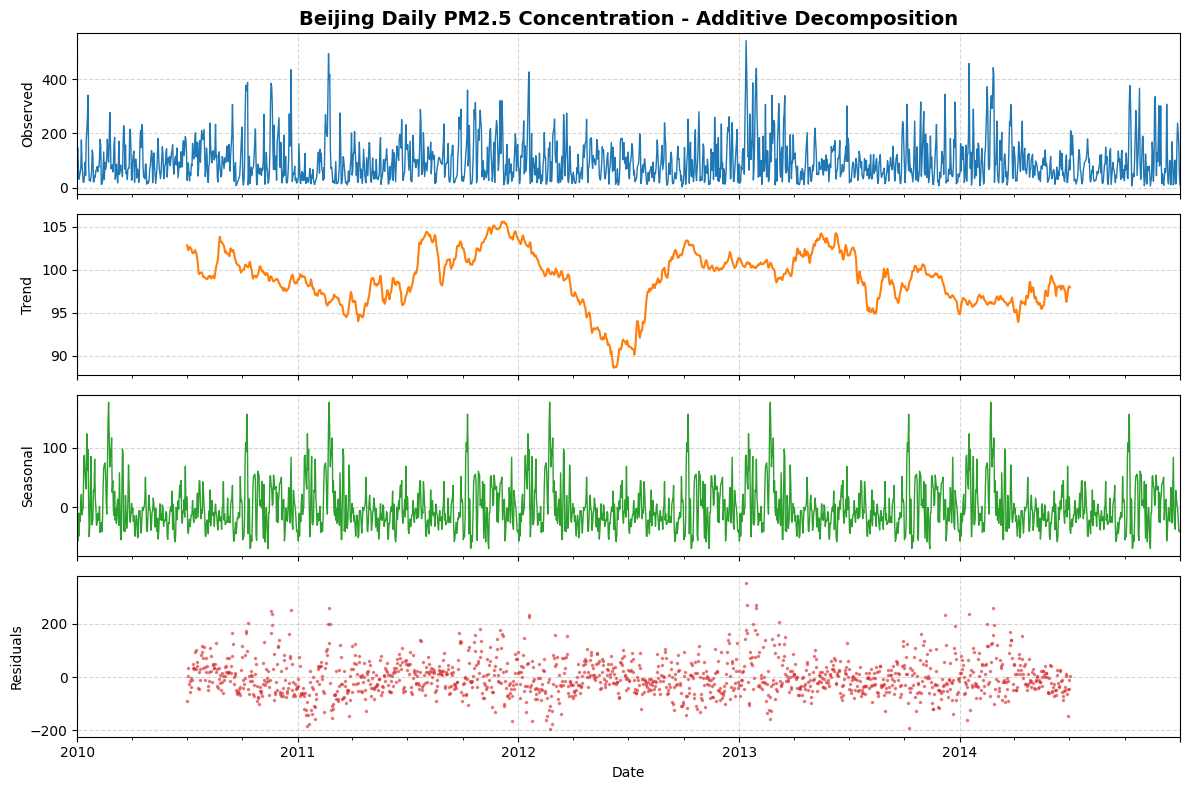

--> Interpretation: The Seasonal component reveals sharp annual spikes during winter months
    (heating season), while the Trend illustrates macro multi-year air quality shifts.

[2/4] Rendering Seasonal Heatmap (Month x Year)...


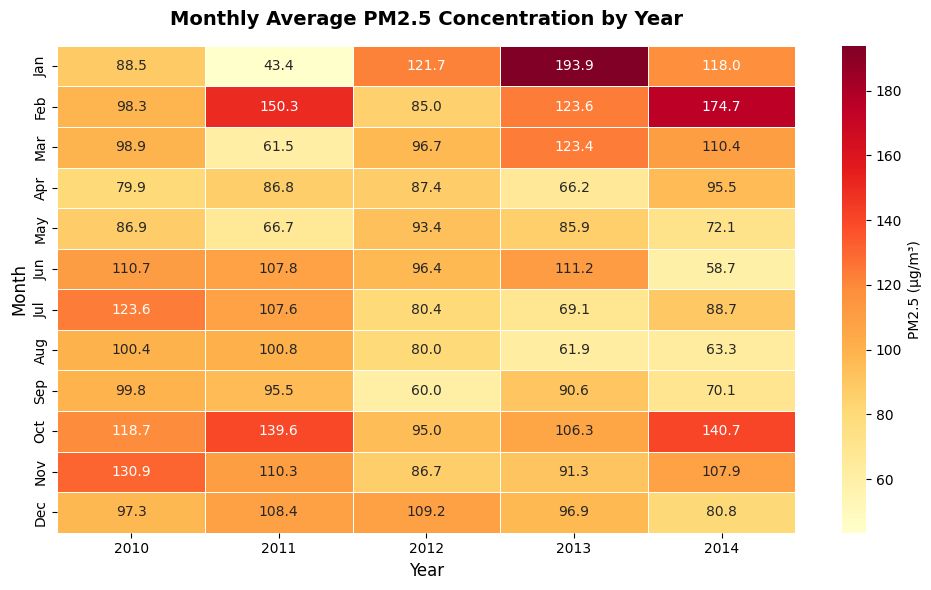

--> Interpretation: High pollution density (darker orange/red) clusters around November-February,
    driven by coal combustion for urban heating and atmospheric stagnation in winter.

[3/4] Rendering Calendar Heatmap...


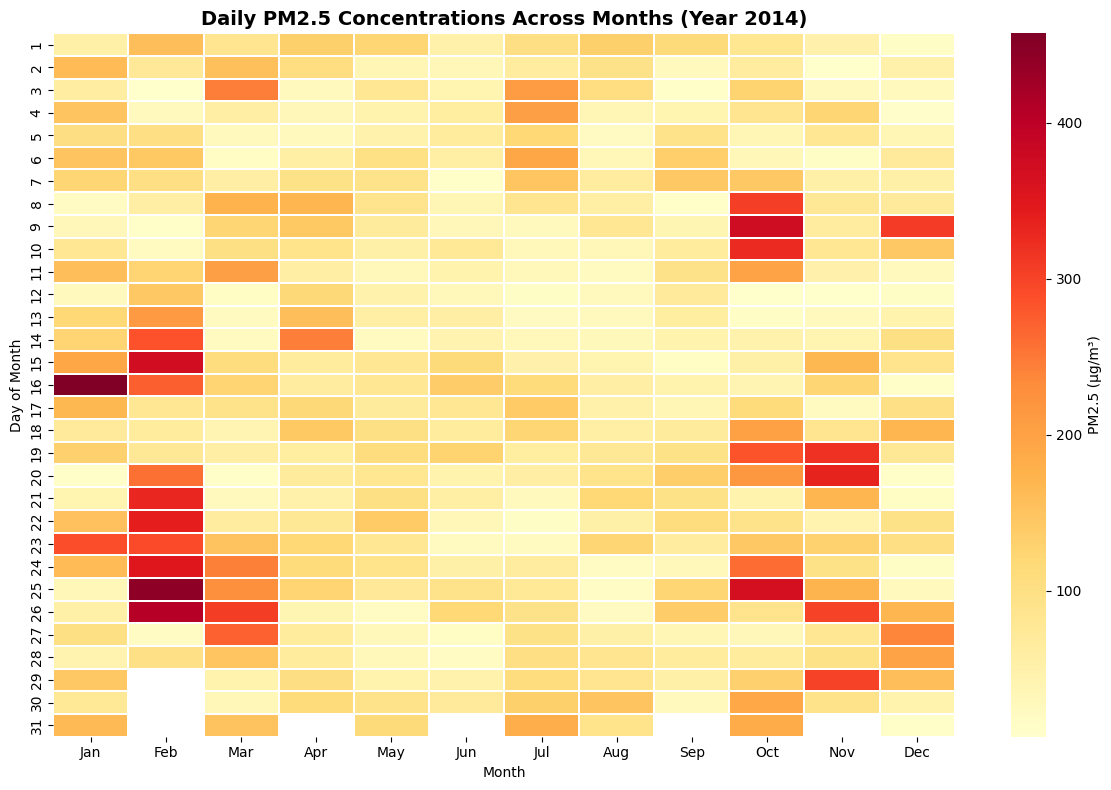

--> Interpretation: The calendar layout highlights episodic severe pollution events (haze spikes),
    showing multi-day persistence where heavy particulate matter stays trapped over consecutive days.

[4/4] Rendering Plotnine (ggplot) Layered Time Series...
<ggplot: (640 x 480)>
--> Interpretation: The LOESS curve isolates overall baseline shifts from extreme daily variances.

Analysis Pipeline Completed Successfully!


In [18]:

def main():
    print("Starting Air Quality Visualization Analysis Workflow...")
    
    # Step 1: Load and preprocess data
    raw_df = load_data()
    daily_df, monthly_df = aggregate_data(raw_df)
    
    # Step 2: Render visualizations
    plot_time_series_decomposition(daily_df)
    plot_seasonal_heatmap(daily_df)
    plot_calendar_heatmap(daily_df)
    plot_ggplot_trend(daily_df)
    
    print("\nAnalysis Pipeline Completed Successfully!")

if __name__ == "__main__":
    main()